# Feature detection

## Harris Corner detection

As always we start with the imports

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

To start, we will use the same checkerboard image as earlier.

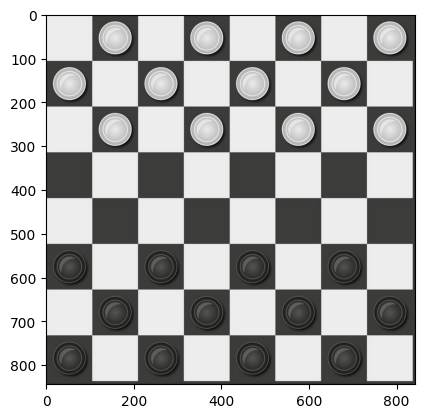

In [ ]:
# Load the checkerboard image and fix its color order for display.
# cv2.imread() reads images in BGR order, but matplotlib expects RGB, so we
# split into channels and re-merge them in reversed (R, G, B) order to get
# correct colors when plotted with plt.imshow().
img = cv2.imread('checkers.png')
# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

### Exercise 2a
Fill in the missing code in the next block. We would like to detect the corners of the image using the OpenCV function [`cv2.cornerHarris`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#gac1fc3598018010880e370e2f709b4345). Afterwards we want to draw the location of the detected corners on the image and display it.

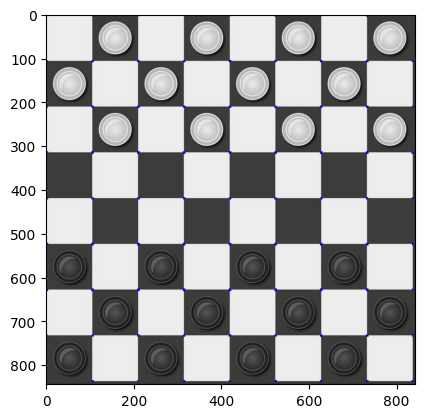

In [ ]:
# We convert the image to grayscale, since cv2.cornerHarris() needs a
# single-channel input to compute intensity gradients. Corners are detected as
# points where the gradient changes sharply in more than one direction
# (unlike an edge, which only changes sharply in one direction).
#   - np.float32(gray) converts the image to floating point, since cornerHarris()
#     requires a float32 input for its internal gradient calculations.
#   - cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04):
#       blockSize=2: size of the neighborhood considered around each pixel when
#         computing the corner response, small here to catch the spaced
#         checkerboard corners.
#       ksize=3: aperture size for the Sobel derivative used internally to
#         compute image gradients. A standard choice for local gradient estimation.
#       k=0.04: the Harris detector's empirical sensitivity constant
#         (typically between 0.04-0.06), controlling the trade-off between
#         detecting true corners and avoiding false positives from edges.
#   - The result 'dst' is a "corner response" image (one float value per pixel
#     indicating how corner) like that location is, not yet a list of discrete
#     corner coordinates.
#   - cv2.dilate(dst, None) grows/thickens the strong-response regions in 'dst'
#     slightly, which makes small isolated corner responses easier to see and
#     mark,  and helps merge together response values that belong to the same
#     real corner.
#   - img[dst > 0.01 * dst.max()] = (0, 0, 255) marks every pixel whose corner
#     response is above 1% of the strongest response found in the whole image;
#     this doubles as both the "corner detection threshold" and the drawing step.
#     Such pixels are painted directly (here as (0, 0, 255), which appears red
#     once the final BGR2RGB-labeled conversion is applied below for display).
# Change image to grayscale.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

### Insert Harris Corner detector here ###
gray = np.float32(gray)
dst = cv2.cornerHarris(gray, 2, 3, 0.04)
dst = cv2.dilate(dst, None)

### Draw the detected corners in the original image here ###
img[dst > 0.01 * dst.max()]= (0, 0, 255)

# Display image.
plt. imshow(img)

## Shi-Tomasi
Next we will try the Shi-Tomasi feature detection method. In OpenCV, that method is implemented as [`cv2.goodFeaturesToTrack`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga1d6bb77486c8f92d79c8793ad995d541). 
Let's start with a different image this time.

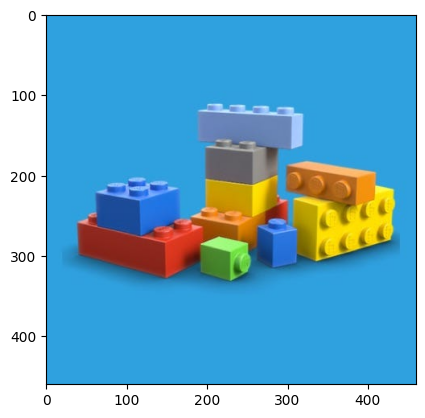

In [ ]:
# Same reasoning as before. Correct the channel order so the image displays
# correctly with matplotlib.
img = cv2.imread('Lego.jpg')
# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

### Exercise 2b
Just like the previous exercise, detect the corners of the image by inserting the missing code, this time using the Shi-Tomasi (good features to track) method. Draw the detected corners on the image. Check the documentation of the function for help.

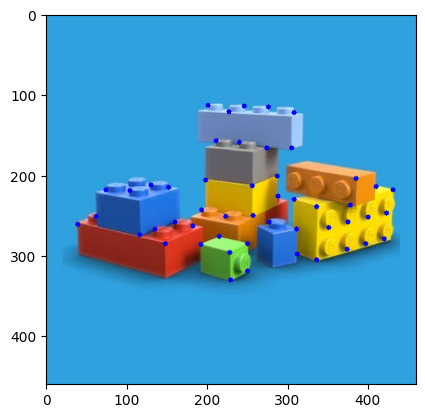

In [ ]:
# Shi-Tomasi is a refinement of the Harris detector that directly ranks and
# selects the strongest, best-separated corners, making it convenient when you
# want a fixed number of good, well-distributed feature points rather than a raw
# per-pixel response map.
#   - Convert to grayscale first, same reasoning as with Harris. The detector
#     needs a single-channel intensity image.
#   - cv2.goodFeaturesToTrack(gray, maxCorners=50, qualityLevel=0.01, minDistance=20):
#       maxCorners=50: return at most the 50 strongest corners found.
#       qualityLevel=0.01: discard any corner whose quality score is below 1%
#         of the single best corner's score, filtering out weak candidates.
#       minDistance=20: enforce at least 20 pixels between any two returned
#         corners, so detections spread out across the image instead of
#         clustering in one area.
#   - np.intp(corners) rounds the returned floating-point corner coordinates
#     to integer pixel indices, since we need whole pixel positions to draw on
#     the image.
#   - For each corner, i.ravel() flattens its (1, 2) shaped array into a plain
#     (x, y) pair, and cv2.circle() draws a small filled (thickness=-1) red
#     circle of radius 3 at that location to visualize the detected feature point.
# Change image to grayscale.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

### Insert goodFeaturesToTrack detector here ###
corners = cv2.goodFeaturesToTrack(gray, 50, 0.01, 20)
corners = np.intp(corners)

### Draw the detected corners in the original image here ###
for i in corners:
    x, y = i.ravel()
    cv2.circle(img, (x, y), 3, (0, 0, 255), -1)

# Display image
plt. imshow(img)

### Exercise 2c
Do a Harris corner detection on the same Lego image and compare the result with the Shi-Tomasi image.

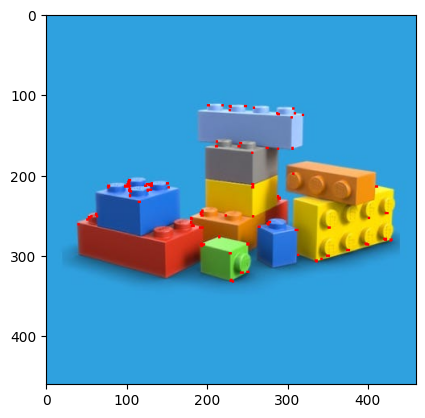

In [6]:
# Running both detectors on the exact same image lets us directly compare their
# behavior. Harris tends to respond more broadly/densely to corner-like gradients,
# while Shi-Tomasi selects a fixed, well-spaced set of the strongest corners,
# so overlaying both approaches on the same input highlights those differences.
# Identical steps to the Harris detection in Exercise 2a. Convert to grayscale,
# cast to float32, run cornerHarris with the same parameters (blockSize=2, ksize=3, k=0.04),
# dilate the response map to make detections more visible, and mark all pixels
# above 1% of the maximum response in red.
img = cv2.imread('Lego.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gray = np.float32(gray)

dst = cv2.cornerHarris(gray, 2, 3, 0.04)
dst = cv2.dilate(dst, None)

img[dst > 0.01 * dst.max()]= (0, 0, 255)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))